In [5]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/raw/ai4i2020.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (10000, 14)


In [6]:
failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]

failure_mode_counts = df[failure_modes].sum().sort_values(
    ascending=False
)

failure_mode_counts

HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64

In [7]:
# Count how many failure modes are present for each machine record

df["Number of Failure Modes"] = df[failure_modes].sum(axis=1)

df["Number of Failure Modes"].value_counts().sort_index()

Number of Failure Modes
0    9652
1     324
2      23
3       1
Name: count, dtype: int64

In [8]:
# Check combinations of failure modes

failure_combinations = (
    df[df["Number of Failure Modes"] > 0][failure_modes]
    .astype(str)
    .agg("".join, axis=1)
    .value_counts()
)

failure_combinations

01000    106
00100     80
00010     78
10000     42
00001     18
00110     11
01010      6
01100      3
10010      2
10001      1
10110      1
Name: count, dtype: int64

In [10]:
# Relationship between each failure mode and overall machine failure


failure_mode_analysis = pd.DataFrame({
    "Failure Mode Count": df[failure_modes].sum(),
    "Machine Failures When Mode Present": [
        df.loc[df[mode] == 1, "Machine failure"].sum()
        for mode in failure_modes
    ],
    "Failure Rate When Mode Present (%)": [
        df.loc[df[mode] == 1, "Machine failure"].mean() * 100
        for mode in failure_modes
    ]
})

failure_mode_analysis

,Failure Mode Count,Machine Failures When Mode Present,Failure Rate When Mode Present (%)
TWF,46,46,100.000000
HDF,115,115,100.000000
PWF,95,95,100.000000
OSF,98,98,100.000000
RNF,19,1,5.263158


In [11]:
# Compare sensor conditions for each failure mode

sensor_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

mode_sensor_summary = {}

for mode in failure_modes:
    mode_sensor_summary[mode] = df.loc[
        df[mode] == 1, sensor_features
    ].mean()

mode_sensor_summary = pd.DataFrame(mode_sensor_summary).T

mode_sensor_summary

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
TWF,300.297826,310.165217,1566.173913,37.836957,216.369565
HDF,302.560870,310.788696,1337.260870,53.166957,107.191304
PWF,300.075789,309.954737,1763.968421,48.514737,101.884211
OSF,300.044898,310.073469,1350.326531,58.370408,207.693878
RNF,300.815789,310.763158,1485.000000,43.673684,124.473684


In [12]:
# Compare average sensor conditions:
# Normal machines vs machines associated with each failure mode

normal_conditions = df.loc[
    df["Machine failure"] == 0,
    sensor_features
].mean()

comparison = mode_sensor_summary.copy()

comparison.loc["Normal (No Machine Failure)"] = normal_conditions

comparison

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
TWF,300.297826,310.165217,1566.173913,37.836957,216.369565
HDF,302.560870,310.788696,1337.260870,53.166957,107.191304
PWF,300.075789,309.954737,1763.968421,48.514737,101.884211
OSF,300.044898,310.073469,1350.326531,58.370408,207.693878
RNF,300.815789,310.763158,1485.000000,43.673684,124.473684
Normal (No Machine Failure),299.973999,309.995570,1540.260014,39.629655,106.693717


In [13]:
# Features used for failure-mode diagnosis

diagnosis_features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

diagnosis_targets = failure_modes

X_diag = df[diagnosis_features].copy()
y_diag = df[diagnosis_targets].copy()

print("Diagnosis input shape:", X_diag.shape)
print("Diagnosis target shape:", y_diag.shape)

print("\nDiagnosis target counts:")
print(y_diag.sum())

Diagnosis input shape: (10000, 6)
Diagnosis target shape: (10000, 5)

Diagnosis target counts:
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64


In [14]:
from sklearn.model_selection import train_test_split

X_diag_train, X_diag_test, y_diag_train, y_diag_test = train_test_split(
    X_diag,
    y_diag,
    test_size=0.20,
    random_state=42
)

print("Training input shape:", X_diag_train.shape)
print("Testing input shape:", X_diag_test.shape)

print("\nTraining target counts:")
print(y_diag_train.sum())

print("\nTesting target counts:")
print(y_diag_test.sum())

Training input shape: (8000, 6)
Testing input shape: (2000, 6)

Training target counts:
TWF    35
HDF    98
PWF    75
OSF    80
RNF    13
dtype: int64

Testing target counts:
TWF    11
HDF    17
PWF    20
OSF    18
RNF     6
dtype: int64


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

diagnosis_categorical_features = ["Type"]

diagnosis_preprocessor = ColumnTransformer(
    transformers=[
        (
            "type",
            OneHotEncoder(handle_unknown="ignore"),
            diagnosis_categorical_features
        )
    ],
    remainder="passthrough"
)

X_diag_train_processed = diagnosis_preprocessor.fit_transform(
    X_diag_train
)

X_diag_test_processed = diagnosis_preprocessor.transform(
    X_diag_test
)

print("Processed training shape:", X_diag_train_processed.shape)
print("Processed testing shape:", X_diag_test_processed.shape)

Processed training shape: (8000, 8)
Processed testing shape: (2000, 8)


In [16]:
from sklearn.multioutput import MultiOutputClassifier
from sklearn.ensemble import RandomForestClassifier

diagnosis_rf = MultiOutputClassifier(
    RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
)

diagnosis_rf.fit(
    X_diag_train_processed,
    y_diag_train
)

print("Multi-label diagnosis model trained successfully!")

Multi-label diagnosis model trained successfully!


In [17]:
from sklearn.metrics import classification_report, confusion_matrix

# Generate predictions
y_diag_pred = diagnosis_rf.predict(X_diag_test_processed)

print("Classification Report:\n")

print(
    classification_report(
        y_diag_test,
        y_diag_pred,
        target_names=diagnosis_targets,
        zero_division=0
    )
)

Classification Report:

              precision    recall  f1-score   support

         TWF       0.50      0.09      0.15        11
         HDF       0.67      0.71      0.69        17
         PWF       0.72      0.65      0.68        20
         OSF       0.86      0.67      0.75        18
         RNF       0.00      0.00      0.00         6

   micro avg       0.73      0.53      0.61        72
   macro avg       0.55      0.42      0.45        72
weighted avg       0.65      0.53      0.56        72
 samples avg       0.02      0.02      0.02        72




TWF Confusion Matrix:
[[1988    1]
 [  10    1]]


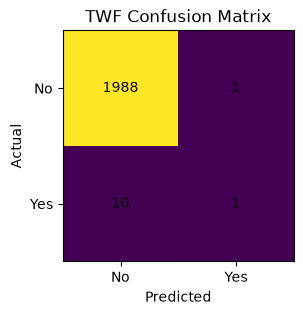


HDF Confusion Matrix:
[[1977    6]
 [   5   12]]


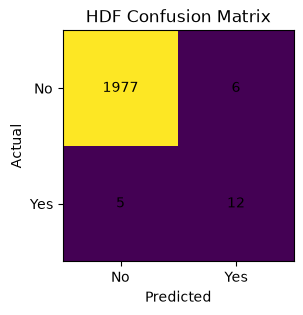


PWF Confusion Matrix:
[[1975    5]
 [   7   13]]


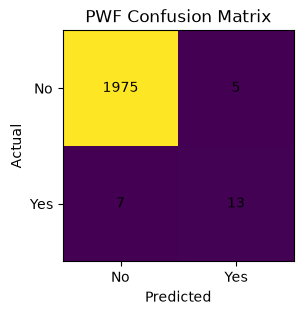


OSF Confusion Matrix:
[[1980    2]
 [   6   12]]


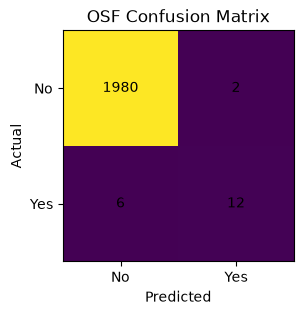


RNF Confusion Matrix:
[[1994    0]
 [   6    0]]


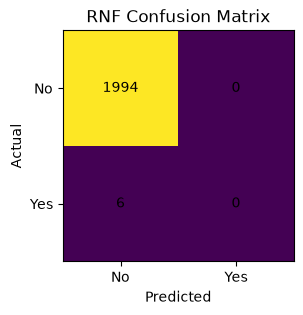

In [18]:
import matplotlib.pyplot as plt

for i, mode in enumerate(diagnosis_targets):

    cm = confusion_matrix(
        y_diag_test.iloc[:, i],
        y_diag_pred[:, i]
    )

    print(f"\n{mode} Confusion Matrix:")
    print(cm)

    plt.figure(figsize=(4, 3))
    plt.imshow(cm)

    plt.title(f"{mode} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.xticks([0, 1], ["No", "Yes"])
    plt.yticks([0, 1], ["No", "Yes"])

    for row in range(2):
        for col in range(2):
            plt.text(
                col,
                row,
                cm[row, col],
                ha="center",
                va="center"
            )

    plt.show()

In [19]:
# Create engineered features for diagnosis

df["Temperature Difference [K]"] = (
    df["Process temperature [K]"] -
    df["Air temperature [K]"]
)

df["Mechanical Power [W]"] = (
    df["Torque [Nm]"] *
    df["Rotational speed [rpm]"] *
    (2 * np.pi / 60)
)

df["Tool Wear Torque Interaction"] = (
    df["Tool wear [min]"] *
    df["Torque [Nm]"]
)

diagnosis_engineered_features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temperature Difference [K]",
    "Mechanical Power [W]",
    "Tool Wear Torque Interaction"
]

X_diag_eng = df[diagnosis_engineered_features].copy()
y_diag_eng = df[diagnosis_targets].copy()

print("Engineered diagnosis input shape:", X_diag_eng.shape)
print("Diagnosis target shape:", y_diag_eng.shape)

Engineered diagnosis input shape: (10000, 9)
Diagnosis target shape: (10000, 5)


In [20]:
X_diag_eng_train, X_diag_eng_test, y_diag_eng_train, y_diag_eng_test = train_test_split(
    X_diag_eng,
    y_diag_eng,
    test_size=0.20,
    random_state=42
)

print("Engineered training input shape:", X_diag_eng_train.shape)
print("Engineered testing input shape:", X_diag_eng_test.shape)

print("\nTraining target counts:")
print(y_diag_eng_train.sum())

print("\nTesting target counts:")
print(y_diag_eng_test.sum())

Engineered training input shape: (8000, 9)
Engineered testing input shape: (2000, 9)

Training target counts:
TWF    35
HDF    98
PWF    75
OSF    80
RNF    13
dtype: int64

Testing target counts:
TWF    11
HDF    17
PWF    20
OSF    18
RNF     6
dtype: int64


In [21]:
diagnosis_eng_preprocessor = ColumnTransformer(
    transformers=[
        (
            "type",
            OneHotEncoder(handle_unknown="ignore"),
            ["Type"]
        )
    ],
    remainder="passthrough"
)

X_diag_eng_train_processed = diagnosis_eng_preprocessor.fit_transform(
    X_diag_eng_train
)

X_diag_eng_test_processed = diagnosis_eng_preprocessor.transform(
    X_diag_eng_test
)

print(
    "Processed engineered training shape:",
    X_diag_eng_train_processed.shape
)

print(
    "Processed engineered testing shape:",
    X_diag_eng_test_processed.shape
)

Processed engineered training shape: (8000, 11)
Processed engineered testing shape: (2000, 11)


In [22]:
diagnosis_eng_rf = MultiOutputClassifier(
    RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
)

diagnosis_eng_rf.fit(
    X_diag_eng_train_processed,
    y_diag_eng_train
)

print("Engineered multi-label diagnosis model trained successfully!")

Engineered multi-label diagnosis model trained successfully!


In [23]:
# Predictions from engineered-feature diagnosis model

y_diag_eng_pred = diagnosis_eng_rf.predict(
    X_diag_eng_test_processed
)

print("Engineered Diagnosis Classification Report:\n")

print(
    classification_report(
        y_diag_eng_test,
        y_diag_eng_pred,
        target_names=diagnosis_targets,
        zero_division=0
    )
)

Engineered Diagnosis Classification Report:

              precision    recall  f1-score   support

         TWF       0.33      0.09      0.14        11
         HDF       0.79      0.88      0.83        17
         PWF       1.00      1.00      1.00        20
         OSF       1.00      1.00      1.00        18
         RNF       0.00      0.00      0.00         6

   micro avg       0.90      0.75      0.82        72
   macro avg       0.62      0.59      0.60        72
weighted avg       0.77      0.75      0.75        72
 samples avg       0.02      0.02      0.02        72



In [24]:
for i, mode in enumerate(diagnosis_targets):

    cm = confusion_matrix(
        y_diag_eng_test.iloc[:, i],
        y_diag_eng_pred[:, i]
    )

    print(f"\n{mode} Confusion Matrix:")
    print(cm)


TWF Confusion Matrix:
[[1987    2]
 [  10    1]]

HDF Confusion Matrix:
[[1979    4]
 [   2   15]]

PWF Confusion Matrix:
[[1980    0]
 [   0   20]]

OSF Confusion Matrix:
[[1982    0]
 [   0   18]]

RNF Confusion Matrix:
[[1994    0]
 [   6    0]]


In [25]:
# Inspect TWF-positive records in the test set

twf_test_cases = X_diag_eng_test[
    y_diag_eng_test["TWF"] == 1
].copy()

twf_test_cases["TWF"] = y_diag_eng_test.loc[
    twf_test_cases.index, "TWF"
]

twf_test_cases

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temperature Difference [K],Mechanical Power [W],Tool Wear Torque Interaction,TWF
6340,H,300.5,309.9,1397,45.9,210,9.4,6714.871554,9639.0,1
5309,M,303.9,313.2,1422,48.0,215,9.3,7147.751605,10320.0,1
8846,M,297.4,308.8,1325,62.4,204,11.4,8658.229353,12729.6,1
1509,L,298.0,308.5,1429,37.7,220,10.5,5641.598783,8294.0,1
1087,H,296.9,307.8,1549,35.8,206,10.9,5807.150244,7374.8,1
3529,L,301.9,310.9,1567,39.0,214,9.0,6399.738395,8346.0,1
2864,H,300.6,309.4,1380,47.6,246,8.8,6878.831274,11709.6,1
9018,L,297.3,308.1,1615,35.4,217,10.8,5986.933120,7681.8,1
6759,L,301.7,311.0,1441,44.3,208,9.3,6684.921704,9214.4,1
7087,L,300.6,310.3,1648,30.5,217,9.7,5263.633771,6618.5,1


In [26]:
twf_comparison = df.groupby("TWF")[
    [
        "Tool wear [min]",
        "Torque [Nm]",
        "Rotational speed [rpm]",
        "Mechanical Power [W]",
        "Tool Wear Torque Interaction"
    ]
].agg(["mean", "median", "min", "max"])

twf_comparison

Tool wear [min]                  Torque [Nm]                     \
               mean median  min  max        mean median   min   max   
TWF                                                                   
0        107.449970  107.0    0  251   39.996845  40.10   3.8  76.6   
1        216.369565  214.5  198  253   37.836957  37.75  16.2  65.3   

    Rotational speed [rpm]                     Mechanical Power [W]  \
                      mean  median   min   max                 mean   
TWF                                                                   
0              1538.649488  1503.0  1168  2886          6280.948416   
1              1566.173913  1516.0  1323  2271          6019.326127   

                                            Tool Wear Torque Interaction  \
          median          min           max                         mean   
TWF                                                                        
0    6272.896591  1148.440610  10469.923005                  4296.761312   
1    6021.176480  3852.660735   9327.304813                  8188.769565   

                               
      median     min      max  
TWF                            
0    3991.35     0.0  16497.0  
1    7982.85  3531.6  13864.4

In [27]:
# Get probability estimates for TWF

twf_probabilities = diagnosis_eng_rf.estimators_[0].predict_proba(
    X_diag_eng_test_processed
)[:, 1]

twf_probability_analysis = pd.DataFrame({
    "Actual_TWF": y_diag_eng_test["TWF"].values,
    "Predicted_TWF": y_diag_eng_pred[:, 0],
    "TWF_Probability": twf_probabilities
})

# Show the actual TWF cases
twf_probability_analysis[
    twf_probability_analysis["Actual_TWF"] == 1
].sort_values(
    "TWF_Probability",
    ascending=False
)

,Actual_TWF,Predicted_TWF,TWF_Probability
5,1,1,0.683333
1838,1,0,0.333333
1309,1,0,0.226667
1938,1,0,0.196667
1661,1,0,0.090000
245,1,0,0.086667
156,1,0,0.050000
697,1,0,0.046667
1628,1,0,0.036667
201,1,0,0.013333


In [28]:
# Create a validation set from the training data
# The final test set remains untouched.

X_diag_train_sub, X_diag_val, y_diag_train_sub, y_diag_val = train_test_split(
    X_diag_eng_train,
    y_diag_eng_train,
    test_size=0.20,
    random_state=42
)

print("Training subset:", X_diag_train_sub.shape)
print("Validation set:", X_diag_val.shape)

print("\nValidation target counts:")
print(y_diag_val.sum())

Training subset: (6400, 9)
Validation set: (1600, 9)

Validation target counts:
TWF     6
HDF    12
PWF    18
OSF    13
RNF     3
dtype: int64


In [29]:
# Preprocess the training subset and validation set

threshold_preprocessor = ColumnTransformer(
    transformers=[
        (
            "type",
            OneHotEncoder(handle_unknown="ignore"),
            ["Type"]
        )
    ],
    remainder="passthrough"
)

X_train_sub_processed = threshold_preprocessor.fit_transform(
    X_diag_train_sub
)

X_val_processed = threshold_preprocessor.transform(
    X_diag_val
)

# Train a fresh multi-label Random Forest
threshold_diagnosis_rf = MultiOutputClassifier(
    RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
)

threshold_diagnosis_rf.fit(
    X_train_sub_processed,
    y_diag_train_sub
)

print("Threshold-tuning model trained successfully!")
print("Training subset processed shape:", X_train_sub_processed.shape)
print("Validation processed shape:", X_val_processed.shape)

Threshold-tuning model trained successfully!
Training subset processed shape: (6400, 11)
Validation processed shape: (1600, 11)


In [30]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

# Get TWF probabilities on validation data
twf_val_prob = threshold_diagnosis_rf.estimators_[0].predict_proba(
    X_val_processed
)[:, 1]

y_twf_val = y_diag_val["TWF"].values

threshold_results = []

for threshold in np.arange(0.10, 0.61, 0.05):

    twf_val_pred = (
        twf_val_prob >= threshold
    ).astype(int)

    precision = precision_score(
        y_twf_val,
        twf_val_pred,
        zero_division=0
    )

    recall = recall_score(
        y_twf_val,
        twf_val_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_twf_val,
        twf_val_pred,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": round(precision, 3),
        "Recall": round(recall, 3),
        "F1": round(f1, 3)
    })

threshold_results = pd.DataFrame(threshold_results)

threshold_results

,Threshold,Precision,Recall,F1
0,0.10,0.042,0.333,0.074
1,0.15,0.027,0.167,0.047
2,0.20,0.036,0.167,0.059
3,0.25,0.056,0.167,0.083
4,0.30,0.000,0.000,0.000
5,0.35,0.000,0.000,0.000
6,0.40,0.000,0.000,0.000
7,0.45,0.000,0.000,0.000
8,0.50,0.000,0.000,0.000
9,0.55,0.000,0.000,0.000


In [31]:
# Verify the documented TWF tool-wear range
# against the actual TWF labels in our dataset.

twf_range = df[
    (df["Tool wear [min]"] >= 200) &
    (df["Tool wear [min]"] <= 240)
]

print("Records with tool wear between 200 and 240:")
print(len(twf_range))

print("\nActual TWF labels within this range:")
print(twf_range["TWF"].value_counts())

print("\nTWF records outside the 200–240 range:")
print(
    df[
        ~(
            (df["Tool wear [min]"] >= 200) &
            (df["Tool wear [min]"] <= 240)
        )
    ]["TWF"].sum()
)

Records with tool wear between 200 and 240:
790

Actual TWF labels within this range:
TWF
0    747
1     43
Name: count, dtype: int64

TWF records outside the 200–240 range:
3


In [32]:
# Inspect TWF records outside the documented 200–240 min range

twf_outside_range = df[
    (df["TWF"] == 1) &
    ~(
        (df["Tool wear [min]"] >= 200) &
        (df["Tool wear [min]"] <= 240)
    )
]

twf_outside_range[
    [
        "UDI",
        "Type",
        "Tool wear [min]",
        "Torque [Nm]",
        "Rotational speed [rpm]",
        "Machine failure",
        "TWF"
    ]
]

,UDI,Type,Tool wear [min],Torque [Nm],Rotational speed [rpm],Machine failure,TWF
1996,1997,M,198,38.2,1416,1,1
2864,2865,H,246,47.6,1380,1,1
5401,5402,M,253,54.8,1454,1,1


In [33]:
# Verify the documented HDF condition

hdf_rule = (
    (df["Temperature Difference [K]"] < 8.6) &
    (df["Rotational speed [rpm]"] < 1380)
)

print("Records matching HDF rule:", hdf_rule.sum())

print("\nActual HDF labels among rule matches:")
print(df.loc[hdf_rule, "HDF"].value_counts())

print("\nActual HDF records:")
print(df["HDF"].sum())

print("\nHDF records NOT captured by the rule:")
print(
    ((df["HDF"] == 1) & (~hdf_rule)).sum()
)

Records matching HDF rule: 115

Actual HDF labels among rule matches:
HDF
1    115
Name: count, dtype: int64

Actual HDF records:
115

HDF records NOT captured by the rule:
0


In [34]:
# Verify the documented PWF condition

pwf_rule = (
    (df["Mechanical Power [W]"] < 3500) |
    (df["Mechanical Power [W]"] > 9000)
)

print("Records matching PWF rule:", pwf_rule.sum())

print("\nActual PWF labels among rule matches:")
print(df.loc[pwf_rule, "PWF"].value_counts())

print("\nActual PWF records:")
print(df["PWF"].sum())

print("\nPWF records NOT captured by the rule:")
print(
    ((df["PWF"] == 1) & (~pwf_rule)).sum()
)

Records matching PWF rule: 95

Actual PWF labels among rule matches:
PWF
1    95
Name: count, dtype: int64

Actual PWF records:
95

PWF records NOT captured by the rule:
0


In [35]:
# Verify the documented OSF condition

osf_rule = (
    ((df["Type"] == "L") & (df["Tool Wear Torque Interaction"] > 11000)) |
    ((df["Type"] == "M") & (df["Tool Wear Torque Interaction"] > 12000)) |
    ((df["Type"] == "H") & (df["Tool Wear Torque Interaction"] > 13000))
)

print("Records matching OSF rule:", osf_rule.sum())

print("\nActual OSF labels among rule matches:")
print(df.loc[osf_rule, "OSF"].value_counts())

print("\nActual OSF records:")
print(df["OSF"].sum())

print("\nOSF records NOT captured by the rule:")
print(
    ((df["OSF"] == 1) & (~osf_rule)).sum()
)

Records matching OSF rule: 98

Actual OSF labels among rule matches:
OSF
1    98
Name: count, dtype: int64

Actual OSF records:
98

OSF records NOT captured by the rule:
0


In [36]:
# Inspect all RNF records

rnf_records = df[df["RNF"] == 1][
    [
        "UDI",
        "Type",
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]",
        "Machine failure",
        "RNF"
    ]
]

rnf_records

,UDI,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,RNF
1221,1222,M,297.0,308.3,1399,46.4,132,0,1
1302,1303,L,298.6,309.8,1505,45.7,144,0,1
1748,1749,H,298.4,307.7,1626,31.1,166,0,1
2072,2073,L,299.6,309.5,1570,35.5,189,0,1
2559,2560,L,299.3,309.0,1447,50.4,140,0,1
3065,3066,M,300.1,309.2,1687,27.7,95,0,1
3452,3453,H,301.6,310.5,1602,32.3,2,0,1
3611,3612,L,301.7,310.9,1405,46.4,207,1,1
5471,5472,L,302.7,312.3,1346,61.2,170,0,1
5489,5490,L,302.6,312.1,1499,35.0,215,0,1


In [37]:
rnf_failures = df[
    (df["RNF"] == 1) &
    (df["Machine failure"] == 1)
]

print("RNF + Machine Failure records:")
print(rnf_failures[failure_modes + ["Machine failure"]])

print("\nFailure modes present in the RNF failure record(s):")
print(rnf_failures[failure_modes].sum())

RNF + Machine Failure records:
      TWF  HDF  PWF  OSF  RNF  Machine failure
3611    1    0    0    0    1                1

Failure modes present in the RNF failure record(s):
TWF    1
HDF    0
PWF    0
OSF    0
RNF    1
dtype: int64


In [38]:
def diagnose_failure(
    machine_type,
    air_temperature,
    process_temperature,
    rotational_speed,
    torque,
    tool_wear
):
    """
    Diagnose verified failure conditions using
    the documented AI4I 2020 rules.
    """

    # Engineered features
    temperature_difference = (
        process_temperature - air_temperature
    )

    mechanical_power = (
        torque *
        rotational_speed *
        (2 * np.pi / 60)
    )

    tool_wear_torque = (
        tool_wear * torque
    )

    detected_modes = []

    # HDF rule
    if (
        temperature_difference < 8.6
        and rotational_speed < 1380
    ):
        detected_modes.append("HDF")

    # PWF rule
    if (
        mechanical_power < 3500
        or mechanical_power > 9000
    ):
        detected_modes.append("PWF")

    # OSF rule
    osf_thresholds = {
        "L": 11000,
        "M": 12000,
        "H": 13000
    }

    if (
        machine_type in osf_thresholds
        and tool_wear_torque > osf_thresholds[machine_type]
    ):
        detected_modes.append("OSF")

    return {
        "detected_failure_modes": detected_modes,
        "temperature_difference": round(
            temperature_difference, 2
        ),
        "mechanical_power": round(
            mechanical_power, 2
        ),
        "tool_wear_torque": round(
            tool_wear_torque, 2
        )
    }


print("Diagnosis function created successfully!")

Diagnosis function created successfully!


In [39]:
# Test the diagnosis function against every record

diagnosis_results = []

for _, row in df.iterrows():

    result = diagnose_failure(
        machine_type=row["Type"],
        air_temperature=row["Air temperature [K]"],
        process_temperature=row["Process temperature [K]"],
        rotational_speed=row["Rotational speed [rpm]"],
        torque=row["Torque [Nm]"],
        tool_wear=row["Tool wear [min]"]
    )

    diagnosis_results.append(result["detected_failure_modes"])


# Convert detected modes into binary columns
diagnosis_predictions = pd.DataFrame({
    "HDF_pred": [
        int("HDF" in modes)
        for modes in diagnosis_results
    ],
    "PWF_pred": [
        int("PWF" in modes)
        for modes in diagnosis_results
    ],
    "OSF_pred": [
        int("OSF" in modes)
        for modes in diagnosis_results
    ]
})

print("Diagnosis predictions created!")
print("\nPredicted counts:")
print(diagnosis_predictions.sum())

Diagnosis predictions created!

Predicted counts:
HDF_pred    115
PWF_pred     95
OSF_pred     98
dtype: int64


In [40]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rule_validation = {}

for mode in ["HDF", "PWF", "OSF"]:

    actual = df[mode]

    predicted = diagnosis_predictions[f"{mode}_pred"]

    rule_validation[mode] = {
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1": f1_score(actual, predicted, zero_division=0)
    }

rule_validation_df = pd.DataFrame(rule_validation).T

rule_validation_df

,Accuracy,Precision,Recall,F1
HDF,1.0,1.0,1.0,1.0
PWF,1.0,1.0,1.0,1.0
OSF,1.0,1.0,1.0,1.0


In [42]:
from sklearn.pipeline import Pipeline

failure_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", random_forest_model)
    ]
)

print("Failure prediction pipeline created successfully!")

NameError: name 'preprocessor' is not defined

In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

failure_categorical_features = ["Type"]

failure_preprocessor = ColumnTransformer(
    transformers=[
        (
            "type",
            OneHotEncoder(handle_unknown="ignore"),
            failure_categorical_features
        )
    ],
    remainder="passthrough"
)

print("Failure-model preprocessor recreated successfully!")

Failure-model preprocessor recreated successfully!


In [44]:
# Recreate the exact feature set used by the final failure model

model_features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temperature Difference [K]",
    "Mechanical Power [W]",
    "Tool Wear Torque Interaction"
]

X = df[model_features].copy()
y = df["Machine failure"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Fit the preprocessor only on training data
failure_preprocessor.fit(X_train)

X_train_check = failure_preprocessor.transform(X_train)
X_test_check = failure_preprocessor.transform(X_test)

print("Training shape:", X_train_check.shape)
print("Testing shape:", X_test_check.shape)

Training shape: (8000, 11)
Testing shape: (2000, 11)


In [45]:
from sklearn.pipeline import Pipeline

failure_pipeline = Pipeline(
    steps=[
        ("preprocessor", failure_preprocessor),
        ("classifier", random_forest_model)
    ]
)

print("Failure prediction pipeline created successfully!")

NameError: name 'random_forest_model' is not defined

In [46]:
import joblib

random_forest_model = joblib.load(
    "../models/indupredict_random_forest.pkl"
)

print("Saved Random Forest loaded successfully!")
print("Model type:", type(random_forest_model).__name__)

Saved Random Forest loaded successfully!
Model type: RandomForestClassifier


In [47]:
from sklearn.pipeline import Pipeline

failure_pipeline = Pipeline(
    steps=[
        ("preprocessor", failure_preprocessor),
        ("classifier", random_forest_model)
    ]
)

print("Failure prediction pipeline created successfully!")

Failure prediction pipeline created successfully!


In [48]:
# Test the complete pipeline on the untouched test set

pipeline_predictions = failure_pipeline.predict(X_test)

# Compare with the saved Random Forest's direct predictions
direct_predictions = random_forest_model.predict(
    X_test_check
)

print(
    "Predictions identical:",
    np.array_equal(
        pipeline_predictions,
        direct_predictions
    )
)

print("\nPipeline prediction counts:")
print(pd.Series(pipeline_predictions).value_counts())

print("\nActual test counts:")
print(y_test.value_counts())

Predictions identical: True

Pipeline prediction counts:
0    1941
1      59
Name: count, dtype: int64

Actual test counts:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [49]:
import joblib

joblib.dump(
    failure_pipeline,
    "../models/indupredict_failure_pipeline.pkl"
)

print("Complete failure prediction pipeline saved successfully!")

Complete failure prediction pipeline saved successfully!


In [50]:
import shap

# Transform the test data using our production preprocessor
X_test_processed = failure_preprocessor.transform(X_test)

# Get feature names after preprocessing
feature_names = failure_preprocessor.get_feature_names_out()

# Create a small sample for SHAP
X_shap_sample = X_test_processed[:200]

# Create SHAP Tree Explainer
shap_explainer = shap.TreeExplainer(
    random_forest_model
)

# Calculate SHAP values
shap_values = shap_explainer.shap_values(
    X_shap_sample
)

print("SHAP explanation created successfully!")
print("Sample shape:", X_shap_sample.shape)
print("Number of feature names:", len(feature_names))

SHAP explanation created successfully!
Sample shape: (200, 11)
Number of feature names: 11


In [51]:
import matplotlib.pyplot as plt

# SHAP values for the failure class
if isinstance(shap_values, list):
    shap_failure_values = shap_values[1]
else:
    shap_failure_values = shap_values[:, :, 1]

# Global feature importance
shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean Absolute SHAP": np.abs(
        shap_failure_values
    ).mean(axis=0)
}).sort_values(
    "Mean Absolute SHAP",
    ascending=False
)

shap_importance

,Feature,Mean Absolute SHAP
9,remainder__Mechanical Power [W],0.106953
5,remainder__Rotational speed [rpm],0.097218
6,remainder__Torque [Nm],0.081473
10,remainder__Tool Wear Torque Interaction,0.071849
8,remainder__Temperature Difference [K],0.063523
7,remainder__Tool wear [min],0.062682
3,remainder__Air temperature [K],0.026211
4,remainder__Process temperature [K],0.015796
1,type__Type_L,0.005006
2,type__Type_M,0.003311


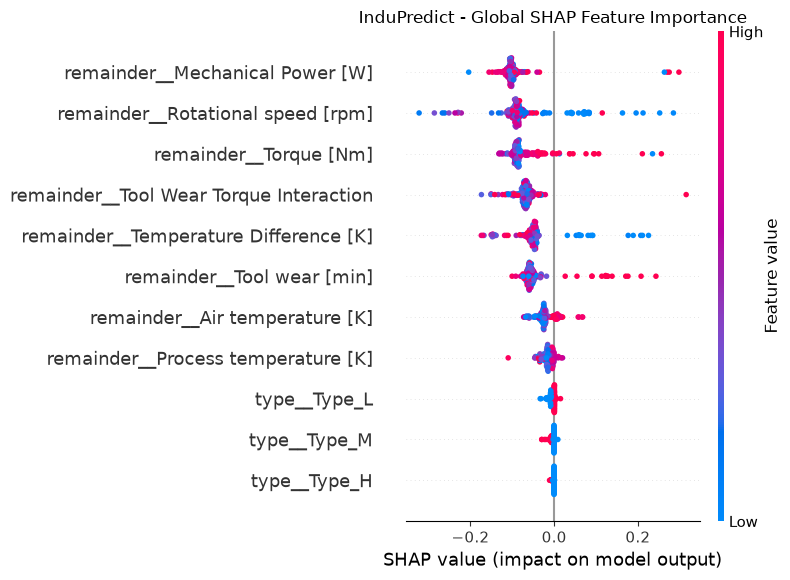

In [52]:
plt.figure(figsize=(10, 6))

shap.summary_plot(
    shap_failure_values,
    X_shap_sample,
    feature_names=feature_names,
    show=False
)

plt.title("InduPredict - Global SHAP Feature Importance")
plt.tight_layout()
plt.show()

In [53]:
# Find test records where the model predicted machine failure

failed_indices = X_test.index[
    pipeline_predictions == 1
]

print("Number of predicted failure cases:", len(failed_indices))

# Select the first predicted-failure case
case_index = failed_indices[0]

print("\nSelected case index:", case_index)

print("\nMachine sensor data:")
print(
    df.loc[
        case_index,
        model_features
    ]
)

print("\nActual machine failure:",
      df.loc[case_index, "Machine failure"])

print("Model prediction:",
      pipeline_predictions[
          list(X_test.index).index(case_index)
      ])

Number of predicted failure cases: 59

Selected case index: 4851

Machine sensor data:
Type                                      L
Air temperature [K]                   303.7
Process temperature [K]               312.1
Rotational speed [rpm]                 1363
Torque [Nm]                            51.8
Tool wear [min]                          90
Temperature Difference [K]              8.4
Mechanical Power [W]            7393.570759
Tool Wear Torque Interaction         4662.0
Name: 4851, dtype: object

Actual machine failure: 1
Model prediction: 1


In [54]:
# Get the processed representation of the selected machine

case_data = X_test.loc[[case_index]]

case_processed = failure_preprocessor.transform(case_data)

# Calculate SHAP values for this individual case
case_shap_values = shap_explainer.shap_values(
    case_processed
)

if isinstance(case_shap_values, list):
    case_failure_shap = case_shap_values[1][0]
else:
    case_failure_shap = case_shap_values[0, :, 1]

# Create a readable explanation table
case_explanation = pd.DataFrame({
    "Feature": feature_names,
    "SHAP Value": case_failure_shap
})

case_explanation["Absolute SHAP"] = (
    case_explanation["SHAP Value"].abs()
)

case_explanation = case_explanation.sort_values(
    "Absolute SHAP",
    ascending=False
)

case_explanation

,Feature,SHAP Value,Absolute SHAP
8,remainder__Temperature Difference [K],0.210861,0.210861
5,remainder__Rotational speed [rpm],0.195656,0.195656
4,remainder__Process temperature [K],-0.109840,0.109840
10,remainder__Tool Wear Torque Interaction,-0.066555,0.066555
9,remainder__Mechanical Power [W],-0.062604,0.062604
7,remainder__Tool wear [min],-0.031277,0.031277
3,remainder__Air temperature [K],0.020169,0.020169
6,remainder__Torque [Nm],0.012155,0.012155
0,type__Type_H,-0.003881,0.003881
1,type__Type_L,-0.003468,0.003468


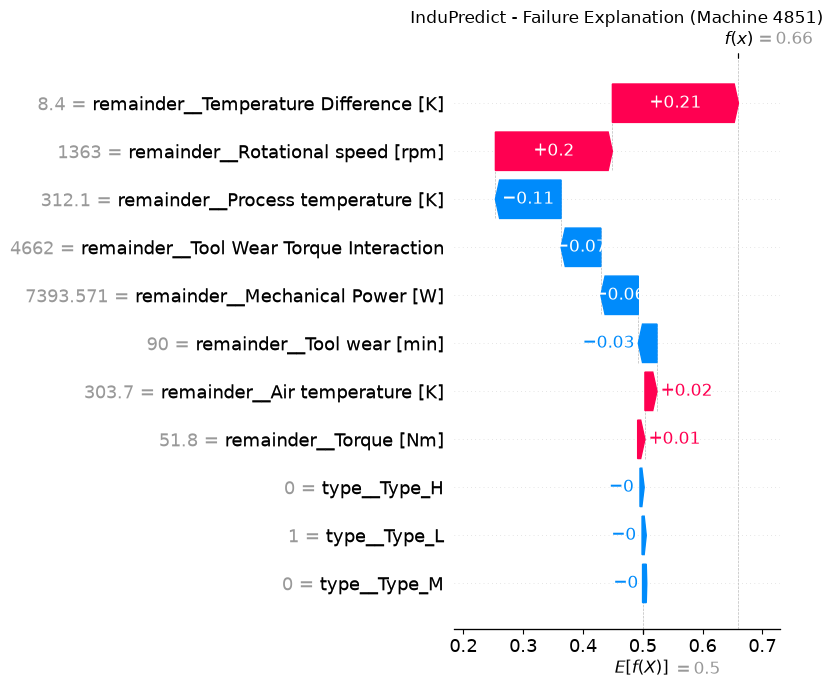

In [58]:
# Get the model's expected/base value for the failure class
shap_base_value = np.asarray(
    shap_explainer.expected_value
)[1]

# Create SHAP explanation for this single machine
case_explanation_object = shap.Explanation(
    values=case_failure_shap,
    base_values=shap_base_value,
    data=case_processed[0],
    feature_names=feature_names
)

# Create waterfall plot
shap.plots.waterfall(
    case_explanation_object,
    max_display=11,
    show=False
)

plt.title(
    f"InduPredict - Failure Explanation (Machine {case_index})"
)

plt.tight_layout()
plt.show()

In [59]:
def explain_prediction(
    machine_type,
    air_temperature,
    process_temperature,
    rotational_speed,
    torque,
    tool_wear
):
    """
    Generate a complete InduPredict prediction,
    SHAP explanation, diagnosis, and maintenance advice.
    """

    # Create one machine record
    machine_data = pd.DataFrame([{
        "Type": machine_type,
        "Air temperature [K]": air_temperature,
        "Process temperature [K]": process_temperature,
        "Rotational speed [rpm]": rotational_speed,
        "Torque [Nm]": torque,
        "Tool wear [min]": tool_wear
    }])

    # Engineered features
    machine_data["Temperature Difference [K]"] = (
        machine_data["Process temperature [K]"] -
        machine_data["Air temperature [K]"]
    )

    machine_data["Mechanical Power [W]"] = (
        machine_data["Torque [Nm]"] *
        machine_data["Rotational speed [rpm]"] *
        (2 * np.pi / 60)
    )

    machine_data["Tool Wear Torque Interaction"] = (
        machine_data["Tool wear [min]"] *
        machine_data["Torque [Nm]"]
    )

    # Machine failure prediction
    prediction = failure_pipeline.predict(machine_data)[0]

    probability = failure_pipeline.predict_proba(
        machine_data
    )[0][1]

    # SHAP explanation
    processed_data = failure_preprocessor.transform(
        machine_data
    )

    shap_values_single = shap_explainer.shap_values(
        processed_data
    )

    if isinstance(shap_values_single, list):
        shap_single = shap_values_single[1][0]
    else:
        shap_single = shap_values_single[0, :, 1]

    explanation = pd.DataFrame({
        "Feature": feature_names,
        "SHAP Value": shap_single
    })

    explanation["Absolute SHAP"] = (
        explanation["SHAP Value"].abs()
    )

    explanation["Direction"] = explanation[
        "SHAP Value"
    ].apply(
        lambda x: "Increases failure prediction"
        if x > 0
        else "Decreases failure prediction"
    )

    explanation = explanation.sort_values(
        "Absolute SHAP",
        ascending=False
    )

    # Rule-based diagnosis
    diagnosis = diagnose_failure(
        machine_type=machine_type,
        air_temperature=air_temperature,
        process_temperature=process_temperature,
        rotational_speed=rotational_speed,
        torque=torque,
        tool_wear=tool_wear
    )

    # Maintenance recommendations
    recommendations = []

    if "HDF" in diagnosis["detected_failure_modes"]:
        recommendations.append(
            "Inspect cooling and heat-dissipation conditions."
        )

    if "PWF" in diagnosis["detected_failure_modes"]:
        recommendations.append(
            "Inspect power/load conditions and operating range."
        )

    if "OSF" in diagnosis["detected_failure_modes"]:
        recommendations.append(
            "Inspect tool wear and excessive mechanical load."
        )

    if not recommendations:
        recommendations.append(
            "No verified HDF/PWF/OSF condition detected; "
            "inspect the machine based on the model explanation."
        )

    return {
        "prediction": int(prediction),
        "failure_probability": float(probability),
        "diagnosis": diagnosis,
        "explanation": explanation,
        "maintenance_recommendations": recommendations
    }


print("InduPredict explanation function created successfully!")

InduPredict explanation function created successfully!


In [60]:
result_4851 = explain_prediction(
    machine_type="L",
    air_temperature=303.7,
    process_temperature=312.1,
    rotational_speed=1363,
    torque=51.8,
    tool_wear=90
)

print("Machine Failure Prediction:")
print(
    "FAILURE" if result_4851["prediction"] == 1
    else "NO FAILURE"
)

print(
    "\nFailure Probability:",
    round(
        result_4851["failure_probability"] * 100,
        2
    ),
    "%"
)

print(
    "\nDetected Failure Modes:"
)

if result_4851["diagnosis"]["detected_failure_modes"]:
    for mode in result_4851["diagnosis"]["detected_failure_modes"]:
        print("-", mode)
else:
    print("- No verified failure mode detected")

print("\nMaintenance Recommendations:")
for recommendation in result_4851["maintenance_recommendations"]:
    print("-", recommendation)

print("\nTop SHAP Contributors:")
print(
    result_4851["explanation"][
        [
            "Feature",
            "SHAP Value",
            "Direction"
        ]
    ].head(5)
)

Machine Failure Prediction:
FAILURE

Failure Probability: 66.0 %

Detected Failure Modes:
- HDF

Maintenance Recommendations:
- Inspect cooling and heat-dissipation conditions.

Top SHAP Contributors:
                                    Feature  SHAP Value  \
8     remainder__Temperature Difference [K]    0.210861   
5         remainder__Rotational speed [rpm]    0.195656   
4        remainder__Process temperature [K]   -0.109840   
10  remainder__Tool Wear Torque Interaction   -0.066555   
9           remainder__Mechanical Power [W]   -0.062604   

                       Direction  
8   Increases failure prediction  
5   Increases failure prediction  
4   Decreases failure prediction  
10  Decreases failure prediction  
9   Decreases failure prediction  


In [61]:
# Clean feature names for user-facing explanations

feature_name_mapping = {
    "remainder__Air temperature [K]":
        "Air Temperature",

    "remainder__Process temperature [K]":
        "Process Temperature",

    "remainder__Rotational speed [rpm]":
        "Rotational Speed",

    "remainder__Torque [Nm]":
        "Torque",

    "remainder__Tool wear [min]":
        "Tool Wear",

    "remainder__Temperature Difference [K]":
        "Temperature Difference",

    "remainder__Mechanical Power [W]":
        "Mechanical Power",

    "remainder__Tool Wear Torque Interaction":
        "Tool Wear × Torque",

    "type__Type_H":
        "Machine Type H",

    "type__Type_L":
        "Machine Type L",

    "type__Type_M":
        "Machine Type M"
}

print("Feature-name mapping created successfully!")

Feature-name mapping created successfully!


In [62]:
def explain_prediction_clean(
    machine_type,
    air_temperature,
    process_temperature,
    rotational_speed,
    torque,
    tool_wear
):
    # Get the existing complete result
    result = explain_prediction(
        machine_type=machine_type,
        air_temperature=air_temperature,
        process_temperature=process_temperature,
        rotational_speed=rotational_speed,
        torque=torque,
        tool_wear=tool_wear
    )

    # Clean SHAP feature names
    result["explanation"]["Feature"] = (
        result["explanation"]["Feature"]
        .map(feature_name_mapping)
        .fillna(result["explanation"]["Feature"])
    )

    return result


print("User-friendly explanation function created successfully!")

User-friendly explanation function created successfully!


In [63]:
clean_result = explain_prediction_clean(
    machine_type="L",
    air_temperature=303.7,
    process_temperature=312.1,
    rotational_speed=1363,
    torque=51.8,
    tool_wear=90
)

print("Machine Failure Prediction:")

if clean_result["prediction"] == 1:
    print("FAILURE")
else:
    print("NO FAILURE")

print(
    "\nFailure Probability:",
    round(
        clean_result["failure_probability"] * 100,
        2
    ),
    "%"
)

print("\nDetected Failure Modes:")

modes = clean_result["diagnosis"]["detected_failure_modes"]

if modes:
    for mode in modes:
        print("-", mode)
else:
    print("- No verified failure mode detected")

print("\nMaintenance Recommendations:")

for recommendation in clean_result[
    "maintenance_recommendations"
]:
    print("-", recommendation)

print("\nTop SHAP Contributors:")

print(
    clean_result["explanation"][
        ["Feature", "SHAP Value", "Direction"]
    ].head(5).to_string(index=False)
)

Machine Failure Prediction:
FAILURE

Failure Probability: 66.0 %

Detected Failure Modes:
- HDF

Maintenance Recommendations:
- Inspect cooling and heat-dissipation conditions.

Top SHAP Contributors:
               Feature  SHAP Value                    Direction
Temperature Difference    0.210861 Increases failure prediction
      Rotational Speed    0.195656 Increases failure prediction
   Process Temperature   -0.109840 Decreases failure prediction
    Tool Wear × Torque   -0.066555 Decreases failure prediction
      Mechanical Power   -0.062604 Decreases failure prediction


In [64]:
import sys

if ".." not in sys.path:
    sys.path.append("..")

from src.diagnosis import diagnose_failure

print("Diagnosis module imported successfully!")

Diagnosis module imported successfully!


In [65]:
module_result = diagnose_failure(
    machine_type="L",
    air_temperature=303.7,
    process_temperature=312.1,
    rotational_speed=1363,
    torque=51.8,
    tool_wear=90
)

print(module_result)

{'detected_failure_modes': ['HDF'], 'temperature_difference': 8.4, 'mechanical_power': 7393.57, 'tool_wear_torque': 4662.0}


In [66]:
from src.maintenance import get_maintenance_recommendations

test_recommendations = get_maintenance_recommendations(
    ["HDF"]
)

print("Maintenance module imported successfully!")
print("\nRecommendations:")
print(test_recommendations)

Maintenance module imported successfully!

Recommendations:
[{'failure_mode': 'HDF', 'action': 'Inspect cooling and heat-dissipation conditions.'}]


In [67]:
multi_recommendations = get_maintenance_recommendations(
    ["HDF", "PWF", "OSF"]
)

for item in multi_recommendations:
    print(
        item["failure_mode"],
        "→",
        item["action"]
    )

HDF → Inspect cooling and heat-dissipation conditions.
PWF → Inspect power/load conditions and operating range.
OSF → Inspect tool wear and excessive mechanical load.


In [68]:
from src.diagnosis import diagnose_failure
from src.maintenance import get_maintenance_recommendations

# Machine 4851
diagnosis_result = diagnose_failure(
    machine_type="L",
    air_temperature=303.7,
    process_temperature=312.1,
    rotational_speed=1363,
    torque=51.8,
    tool_wear=90
)

detected_modes = diagnosis_result[
    "detected_failure_modes"
]

maintenance_result = get_maintenance_recommendations(
    detected_modes
)

print("Detected Failure Modes:")
print(detected_modes)

print("\nMaintenance Recommendations:")

for item in maintenance_result:
    print(
        f"{item['failure_mode']} → "
        f"{item['action']}"
    )

Detected Failure Modes:
['HDF']

Maintenance Recommendations:
HDF → Inspect cooling and heat-dissipation conditions.
